# Resistiviy
-------
Today's goals
* DC Experiment
* What we measure
* How we measure it

## The experiment

* Push current into the ground at one electrode (A) and pull it out at another (B)
* Current flows through the subsurface: it channels into conductors and around resistors
* Measure the voltage between two other electrodes (M and N)

**Question for today:** how does that voltage tell us about the rock?

![survey](https://mineclosure.gtk.fi/wp-content/uploads/2018/09/KUVA9_v2-1024x722.jpg)

## What controls conductivity in rocks? Or in materials in general
* Material composition - having free electrons as an intrinsic property facilitates current flow
* Temperature - increasing temperature, increases the energy, allowing electrons to jump to conduction bands, freeing up ‘holes’ in lower bands and facilitating current flow
* Impurities - cause defects in the lattice creating holes or ‘tears’ or adding holes or extra electrons
* Physical structure: in well ordered structures, charges can move easily (amorphous structures can slow down the flow)
* Presence of free charges - think fluids

In [1]:
from geoana.em.static import DipoleHalfSpace
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

In [2]:
def fig1(A=None, B=None, draw_source=False, draw_potential=False):
    if A is None:
        A = [-20, 0, 0]
    if B is None:
        B = [20, 0, 0]
    dip = DipoleHalfSpace(0.01, A, B)

    x = np.linspace(-40, 40, 256)
    z = np.linspace(-40, 0, 128)
    xyz = np.meshgrid(x, [0], z)
    
    V = dip.potential(xyz).squeeze()
    E = dip.electric_field(xyz).squeeze()

    draw_source = draw_source or draw_potential
    if draw_source:
        fig, axs = plt.subplots(2, 1, sharex=True, dpi=200)
        ax = axs[1]
        fig.subplots_adjust(hspace=0)
    else:
        fig = plt.figure(dpi=200)
        ax = plt.gca()
        axs = ax
    
    im = ax.pcolormesh(x, z, V.T, norm=mpl.colors.SymLogNorm(0.0001), cmap='seismic')
    ax.streamplot(x, z, E[...,0].T, E[...,2].T)
    if draw_source:
        ax_circ = axs[0]
        ax_circ.axis('off')
        
        # Draw a simple battery + resistor + wire
        ax_circ.plot([-20,-20, -2], [0,1, 1], color='k')       # wire
        ax_circ.plot([-2, -2], [0.5, 1.5], color='k', lw=2)  # battery left
        ax_circ.plot([2, 2], [0.8, 1.2], color='k', lw=1)  # battery right
        ax_circ.plot([2, 20, 20], [1, 1, 0], color='k')     # wire
        ax_circ.text(-22, 0, 'A', fontsize=12, horizontalalignment='right', verticalalignment='bottom')
        ax_circ.text(22, 0, 'B', fontsize=12, horizontalalignment='left', verticalalignment='bottom')


        if draw_potential:
            ax_circ.plot([-5, -5, -1], [0, 0.3, 0.3], color='b')
            ax_circ.plot([3, 7, 7], [0.3, 0.3, 0], color='b')
            ax_circ.text(1, 0.3, 'V', fontsize=12, horizontalalignment='center', verticalalignment='center')
            circ = mpl.patches.Ellipse([1,0.3], height=0.5,width=4, fill=False,edgecolor='b')
            ax_circ.add_patch(circ)
            ax_circ.text(-6, 0, 'M', fontsize=12, horizontalalignment='right', verticalalignment='bottom')
            ax_circ.text(8, 0, 'N', fontsize=12, horizontalalignment='left', verticalalignment='bottom')

        ax_circ.set_ylim([0, 5])
    else:
        ax.set_aspect(1)
    cb = plt.colorbar(im, shrink=0.5, ax=axs)
    
    cb.set_label('Potential (V)')
    ax.set_xlabel('X (m)')
    ax.set_ylabel('Z (m)')

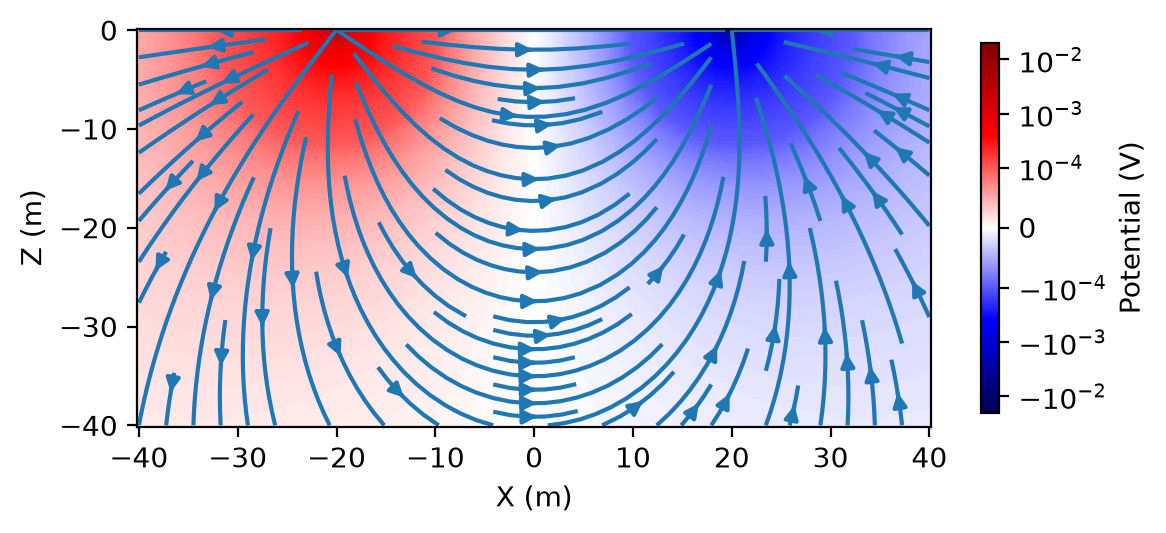

In [3]:
fig1()

## Two rules

**Rule 1: Current is conserved.**
Current flowing into a volume must flow out, unless charge builds up inside.

$$\partial_t \rho_e + \nabla \cdot \vec{J} = q$$

For DC nothing changes in time ($\partial_t \rho_e = 0$), so all current injected at an electrode flows outward:

$$\nabla \cdot \vec{J} = q$$

**Rule 2: Ohm's law.**
* $V = IR$ describes an *object* (depends on its size and shape)
* $\vec{J} = \sigma \vec{E}$ describes a *material* at a point

We want the second form, because we're after the rock, not the geometry.

**Put together** with $\vec{E} = -\nabla \phi$:

$$-\nabla \cdot \sigma \nabla \phi = q$$

For uniform ground ($\sigma$ constant), this is just Poisson's equation.

#### Units
* $\sigma$: electrical conductivity, Siemens per meter (S/m)
* $q $ \[=\] C/($m^3$ s)= (C/s) (1/$m^3$) i.e. the current source per unit volume
* $\rho = 1/\sigma$: electrical resistivity, Ohm meters ($\Omega$m)

## One Electrode

### If we were to bury our electrode in the ground or put it in the ocean (wholespace)
Current $I$ spreads out equally in all directions. At distance $r$ it passes through a sphere of area $4\pi r^2$:

$$J = \frac{I}{4\pi r^2} \quad\rightarrow\quad E = \frac{J}{\sigma} = \frac{I}{4\pi\sigma r^2}$$

Integrating $E$ from $r$ out to $\infty$ (where $\phi = 0$):

$$\phi = \frac{I}{4\pi\sigma}\frac{1}{r}$$

### On the surface (halfspace)
No current can flow into the air, so it only spreads through a hemisphere, $2\pi r^2$. Half the area means double the potential:

$$\phi = \frac{I}{2\pi\sigma}\frac{1}{r}$$

**What controls the potential?**
* More current $I$: higher potential
* More conductive ground (bigger $\sigma$): lower potential, current flows easily
* Farther away (bigger $r$): lower potential

In [4]:
def fig2():
    A = [0, 0, 0]
    B = [1E100, 0, 0] # put B effectively at infinity to show a single current source
    dip = DipoleHalfSpace(0.01, A, B)

    x = np.linspace(-40, 40, 256)
    z = np.linspace(-40, 0, 128)
    xyz = np.meshgrid(x, [0], z)
    
    V = dip.potential(xyz).squeeze()
    E = dip.electric_field(xyz).squeeze()
    
    plt.figure(dpi=200)
    ax = plt.gca()
    
    im = ax.pcolormesh(x, z, V.T, norm=mpl.colors.LogNorm(), cmap='Reds')
    ax.set_aspect(1)
    cb = plt.colorbar(im, shrink=0.5)
    
    cb.set_label('Potential (V)')
    ax.set_xlabel('X (m)')
    ax.set_ylabel('Z (m)')
    
    ax.streamplot(x, z, E[...,0].T, E[...,2].T)

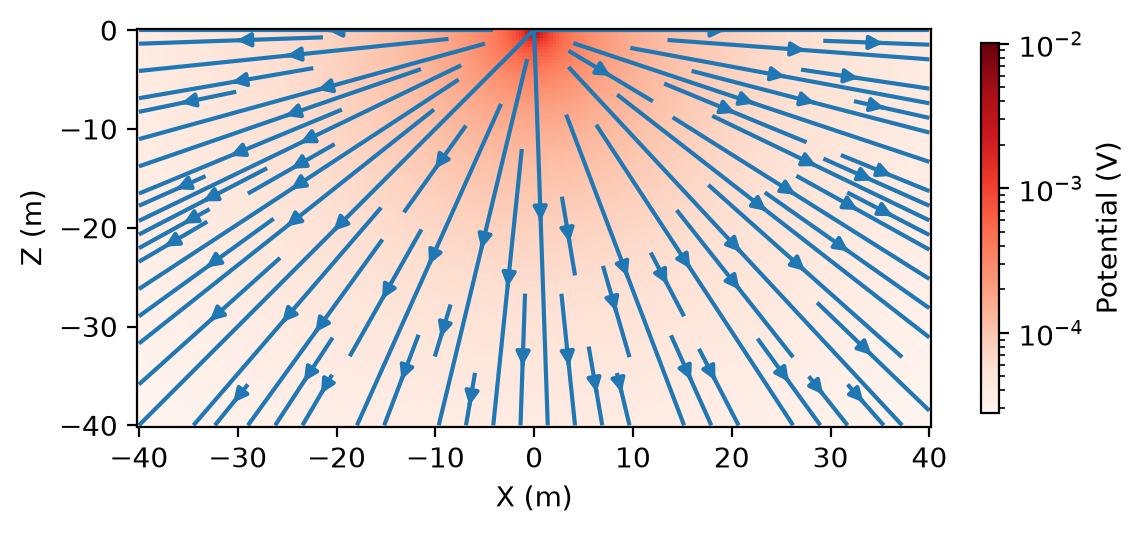

In [5]:
fig2()

## Four electrodes

### Step 1: Current in at A, out at B
Add the two single-electrode solutions together (B is a sink, so it gets a minus sign):

$$\phi = \frac{I}{2 \pi \sigma}\left(\frac{1}{r_A} - \frac{1}{r_B}\right)$$

where $r_A$ and $r_B$ are the distances from A and B.

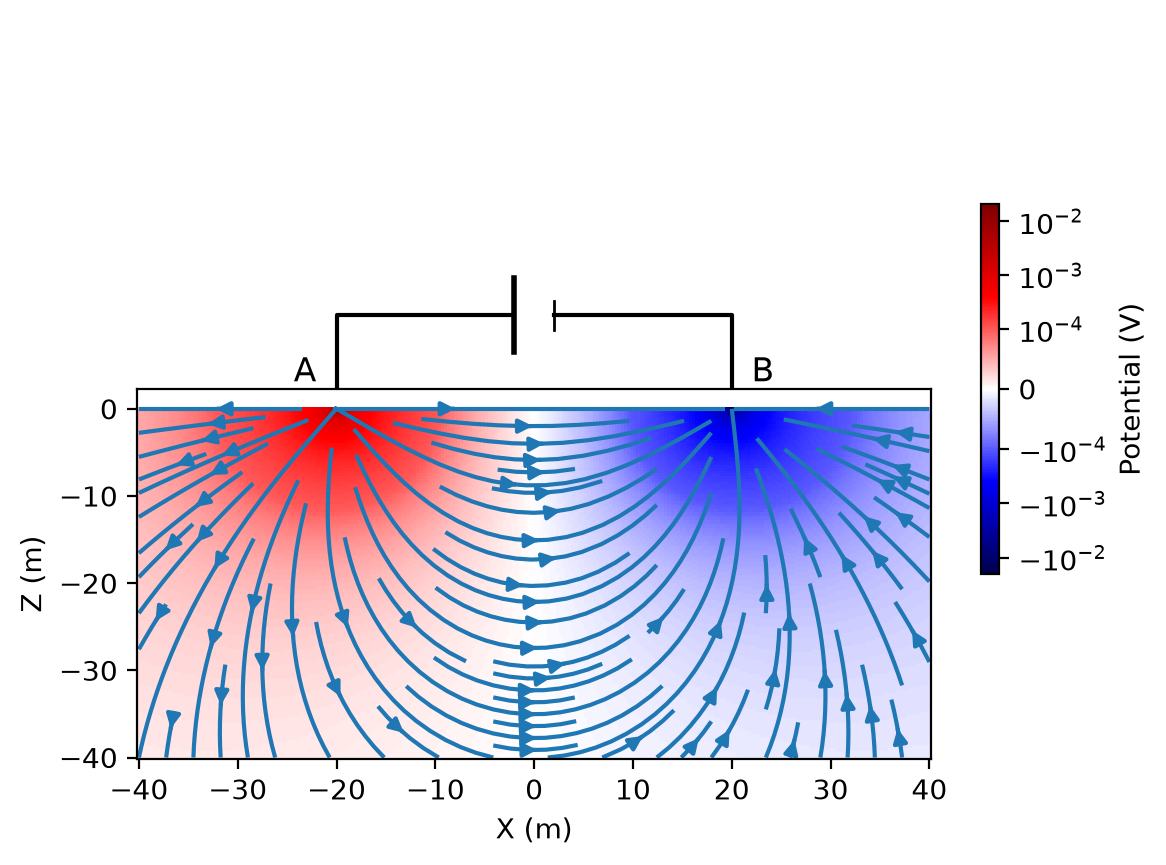

In [6]:
fig1(draw_source=True)

### Step 2: Measure the voltage between M and N
$$\Delta \phi = \phi_M - \phi_N = \frac{I}{2 \pi \sigma}\left(\frac{1}{AM} - \frac{1}{BM} - \frac{1}{AN} + \frac{1}{BN} \right)$$

($AM$ is the distance between A and M, and so on.)

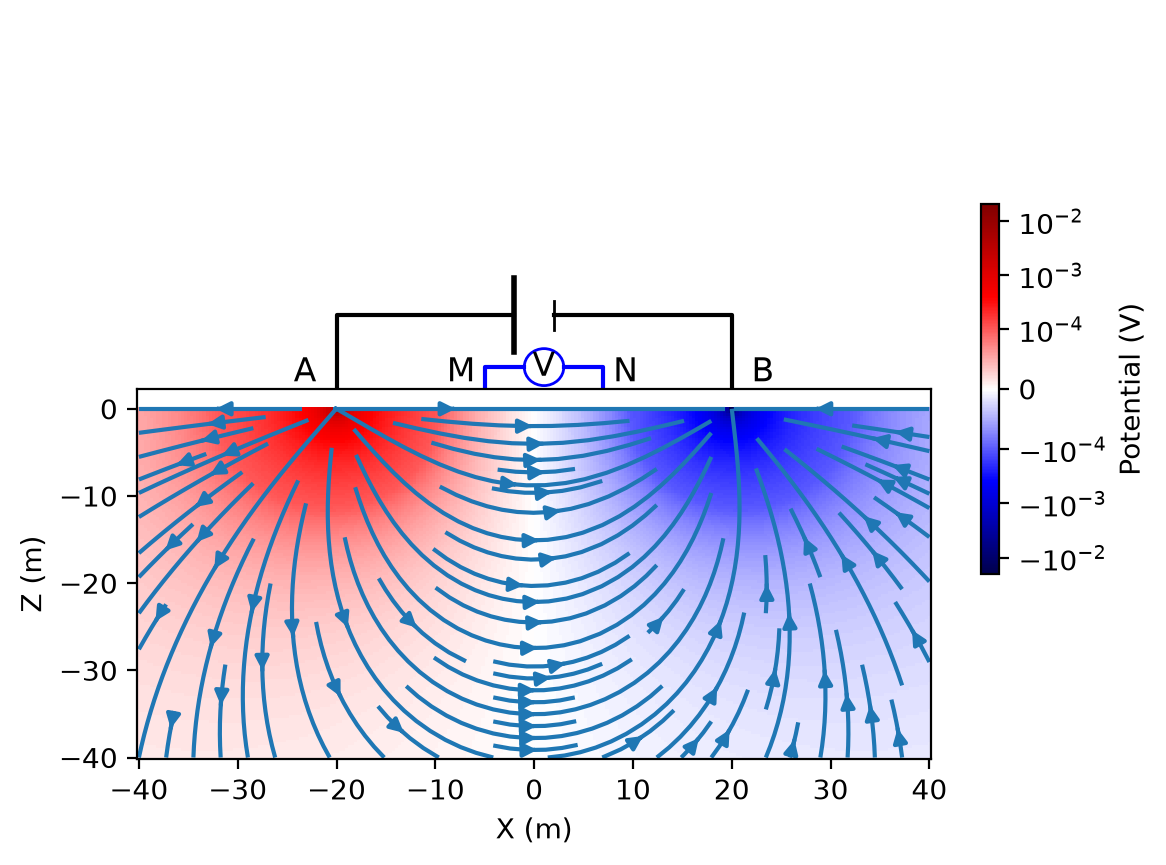

In [7]:
fig1(draw_potential=True)

### Why four electrodes and not two?
* Every electrode has a *contact resistance* with the ground (often hundreds to thousands of Ohms)
* A and B: contact resistance limits how much current we can push, but we measure $I$ directly, so it doesn't bias the result
* M and N: the voltmeter draws almost no current, so their contact resistance doesn't affect $\Delta\phi$
* This is why we water electrodes in the field, and why bad contacts show up as noisy data

### Step 3: Solve for the rock
Collect all the distances into one *geometric factor* $G$:

$$\Delta \phi = \frac{I}{\sigma} G \qquad G = \frac{1}{2\pi}\left(\frac{1}{AM} - \frac{1}{BM} - \frac{1}{AN} + \frac{1}{BN} \right)$$

We know $I$ (we injected it), $G$ (we laid out the electrodes), and $\Delta\phi$ (we measured it), so:

$$\rho = \frac{1}{\sigma} = \frac{\Delta \phi}{I}\frac{1}{G}$$

**Caveat:** this is exact only if the ground is uniform. Anywhere else, it gives an **apparent resistivity**, $\rho_a$. More on that next lecture.

### Example (Wenner array, electrodes evenly spaced at $a$)
$G = 1/(2\pi a)$, so $\rho_a = 2\pi a \, \Delta\phi / I$

$a$ = 10 m, $I$ = 0.1 A, $\Delta\phi$ = 0.05 V

What did we measure? 
permafrost, clays, gravels and sand, or I have no idea?

![materials](resources/res-range-clr.png)

### How do you measure voltage anyways??
With a voltmeter!

### Analogue voltmeters
![analogue](https://cdn11.bigcommerce.com/s-g7j5rv61k1/images/stencil/1280x1280/products/426/480/SS20408-2__84790.1575924284.jpg?c=1)

* Connect in parallel with a known high resistance resistor
* A very small current goes through this wire
* Currents create magnetic fields!
* Magnetic field pushes on the dial!

### Digital Voltmeters
* Work using Analogue to Digital converters
* Compares voltage to many reference voltages.

![ADC](https://www.electronics-tutorials.ws/wp-content/uploads/2020/09/comb75.gif)

# Geophysical Equipment
## All-in-one
### ABEM Terrameter
![abem](https://www.mining-technology.com/wp-content/uploads/sites/19/2016/11/Resistivity_IP_ABEM_Terrameter_LS_2.jpg)

### Supersting R8
![SS-R8](resources/Superstingr8.png)

### Sting R1
![Sting R1](https://pe2bz.philpem.me.uk/Detect-Sense/Products/Resistivity/stingr1.jpg)

## Next time
Everything today assumed uniform ground. Next lecture: what happens when it isn't, and what that 31 $\Omega$m actually tells us.